<a href="https://colab.research.google.com/github/careen-tech/COU07506_labs/blob/main/COU07506_Week04_240242409662.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# WEEK 4 — z-Transform Laboratory:
# Poles, Zeros and Stability

**Institution:** Dar es Salaam Institute of Technology

**Department:** Computer Studies Department

**Module:** Digital Signal Processing

**Module Code:** COU07506

**Student Name:** Careen Reginald

**Registration Number:** 240242409662

**Class:** BEng24CoE1

**Academic Year:** 2026/2027

**Date:** 25/11/2026



## Laboratory Objectives

1. Find poles, zeros and frequency responses of
   transfer functions using SciPy.

2. Use residuez to obtain the inverse z-transform
   and verify the results using lfilter.

3. Investigate the relationship between pole
   positions, stability, resonance and impulse response.

4. Design a simple resonator by placing poles.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Libraries imported successfully!")


Libraries imported successfully!



## Pre-lab Preparation

### Question (a): Finding Poles and Stability

Given:

$$H(z)=\frac{1}{1-0.9z^{-1}+0.81z^{-2}}$$

Setting the denominator equal to zero:

$$z^2-0.9z+0.81=0$$

Using the quadratic formula:

$$z=\frac{0.9\pm\sqrt{-2.43}}{2}$$

Therefore, the poles are:

$$p_1=0.45+j0.779423$$

$$p_2=0.45-j0.779423$$

The magnitude of each pole is:

$$|p|=\sqrt{0.45^2+0.779423^2}=0.9$$

Since both poles lie strictly inside the unit circle,
the causal system is BIBO stable.


In [2]:

# Pre-lab question (a): Verify poles and stability

a = [1, -0.9, 0.81]

poles = np.roots(a)

print("Poles:", np.round(poles, 6))

print("Pole magnitudes:", np.abs(poles))

print("System is stable:",
      np.all(np.abs(poles) < 1))


Poles: [0.45+0.779423j 0.45-0.779423j]
Pole magnitudes: [0.9 0.9]
System is stable: True



### Question (b): Partial-Fraction Expansion

Given:

$$X(z)=\frac{1}{(1-0.5z^{-1})(1-0.25z^{-1})}$$

Expressing the function in partial fractions:

$$X(z)=\frac{A}{1-0.5z^{-1}}+
\frac{B}{1-0.25z^{-1}}$$

Multiplying by the common denominator:

$$1=A(1-0.25z^{-1})+B(1-0.5z^{-1})$$

Equating coefficients:

$$A+B=1$$

$$0.25A+0.5B=0$$

Solving simultaneously:

$$A=2,\qquad B=-1$$

Therefore, the partial-fraction expansion is:

$$X(z)=\frac{2}{1-0.5z^{-1}}-
\frac{1}{1-0.25z^{-1}}$$

Assuming a causal sequence, the inverse z-transform is:

$$x(n)=[2(0.5)^n-(0.25)^n]u(n)$$


In [3]:

# Pre-lab question (b): Verify partial fractions

b = [1]

a = [1, -0.75, 0.125]

r, p, k = signal.residuez(b, a)

print("Residues:", r)

print("Poles:", p)

print("Direct terms:", k)


Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct terms: []



## Task 4.1 — A Pole-Zero Plotting Function

**Objective:** To implement a pole-zero plotting
function using Python and SciPy, investigate the
frequency response of a discrete-time system
and determine its stability.


In [4]:

# Task 4.1: Pole-zero plotting function

def zplane(b, a, ax=None):

    # Make numerator and denominator lengths equal
    N = max(len(b), len(a))

    b_pad = np.pad(b, (0, N - len(b)))
    a_pad = np.pad(a, (0, N - len(a)))

    # Calculate zeros, poles and gain
    z, p, k = signal.tf2zpk(b_pad, a_pad)

    if ax is None:
        ax = plt.gca()

    # Draw the unit circle
    th = np.linspace(0, 2*np.pi, 400)

    ax.plot(np.cos(th), np.sin(th),
            "k--", lw=0.8)

    # Plot zeros
    ax.plot(z.real, z.imag, "o",
            mfc="none", ms=9, label="Zeros")

    # Plot poles
    ax.plot(p.real, p.imag, "x",
            ms=9, mew=2, label="Poles")

    ax.axhline(0, color="grey", linewidth=0.7)
    ax.axvline(0, color="grey", linewidth=0.7)

    ax.set_aspect("equal")
    ax.set_xlabel("Real part")
    ax.set_ylabel("Imaginary part")
    ax.set_title("Pole-Zero Diagram")
    ax.legend()
    ax.grid(True)

    return z, p


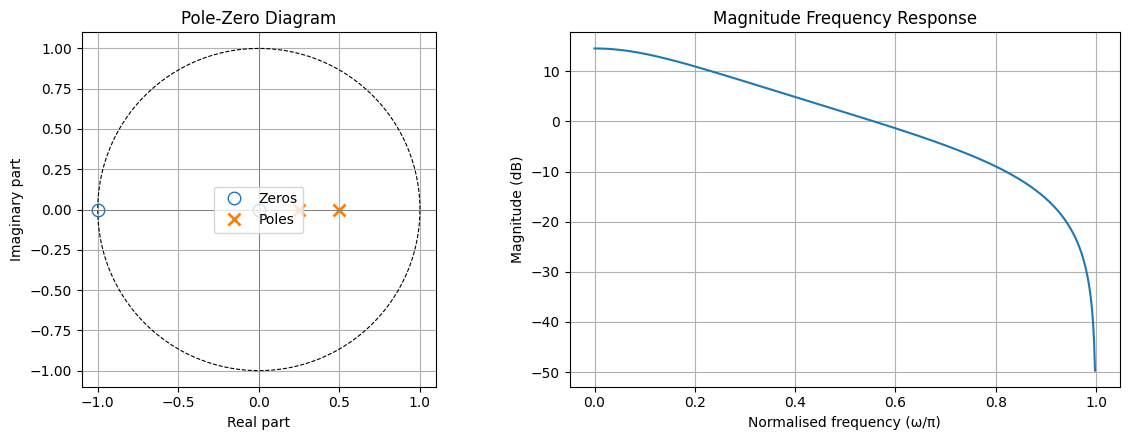

Zeros: [-1.  0.]
Poles: [0.5  0.25]
Pole magnitudes: [0.5  0.25]
System is stable: True


In [5]:

# Transfer function coefficients

b = [1, 1]
a = [1, -0.75, 0.125]

# Create two subplots
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, 4.5)
)

# Plot poles and zeros
z, p = zplane(b, a, ax1)

# Calculate frequency response
w, H = signal.freqz(b, a, worN=512)

# Convert magnitude to decibels
magnitude_db = 20*np.log10(
    np.maximum(np.abs(H), 1e-12)
)

# Plot frequency response
ax2.plot(w/np.pi, magnitude_db)

ax2.set_title("Magnitude Frequency Response")
ax2.set_xlabel("Normalised frequency (ω/π)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid(True)

plt.tight_layout()
plt.show()

# Display results
print("Zeros:", z)
print("Poles:", p)
print("Pole magnitudes:", np.abs(p))
print("System is stable:", np.all(np.abs(p) < 1))


In [6]:

# Verify DC and Nyquist frequency responses

w_test = np.array([0, np.pi])

_, H_test = signal.freqz(b, a, worN=w_test)

dc_gain = np.abs(H_test[0])
nyquist_gain = np.abs(H_test[1])

print("DC gain:", round(dc_gain, 6))

print("DC gain in dB:",
      round(20*np.log10(dc_gain), 2))

print("Nyquist gain:",
      round(nyquist_gain, 6))

print("Filter behaviour: Low-pass")


DC gain: 5.333333
DC gain in dB: 14.54
Nyquist gain: 0.0
Filter behaviour: Low-pass


### Task 4.1 — Observations and Discussion

A reusable pole-zero plotting function was successfully implemented using NumPy, Matplotlib and SciPy.

The transfer function produced two poles located at 0.5 and 0.25, and two zeros located at −1 and 0.

The pole-zero diagram showed that both poles were located strictly inside the unit circle. Therefore, the causal discrete-time system was identified as BIBO stable.

The frequency response was calculated using SciPy's freqz function. The magnitude response was highest at zero frequency and gradually decreased as the frequency increased.

The DC gain was approximately 5.333333, corresponding to 14.54 dB. The zero located at z = −1 suppressed the response at the Nyquist frequency.

These characteristics demonstrated that the system exhibits low-pass filter behaviour.

The experiment demonstrated how the locations of poles and zeros influence the stability and frequency response of digital systems.


## Task 4.2 — Inverse z-Transform with residuez

**Objective:** To obtain the inverse z-transform
using partial-fraction expansion with SciPy's
residuez function and verify the results using
the lfilter function.


In [7]:

# Task 4.2: Inverse z-transform

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# System coefficients
b = [1]
a = [1, -0.75, 0.125]

# Partial-fraction expansion
r, p, k = signal.residuez(b, a)

print("Residues:", r)
print("Poles:", p)
print("Direct terms:", k)

# Sample indices
n = np.arange(10)

# Calculate inverse z-transform
x_pf = sum(
    ri * pi**n for ri, pi in zip(r, p)
).real

# Generate unit impulse
impulse = np.zeros(10)
impulse[0] = 1

# Calculate response using lfilter
x_lf = signal.lfilter(b, a, impulse)

print("Inverse z-transform:",
      np.round(x_pf, 6))

print("lfilter response:",
      np.round(x_lf, 6))

print("Results match:",
      np.allclose(x_pf, x_lf))


Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct terms: []
Inverse z-transform: [1.       0.75     0.4375   0.234375 0.121094 0.061523 0.031006 0.015564
 0.007797 0.003902]
lfilter response: [1.       0.75     0.4375   0.234375 0.121094 0.061523 0.031006 0.015564
 0.007797 0.003902]
Results match: True


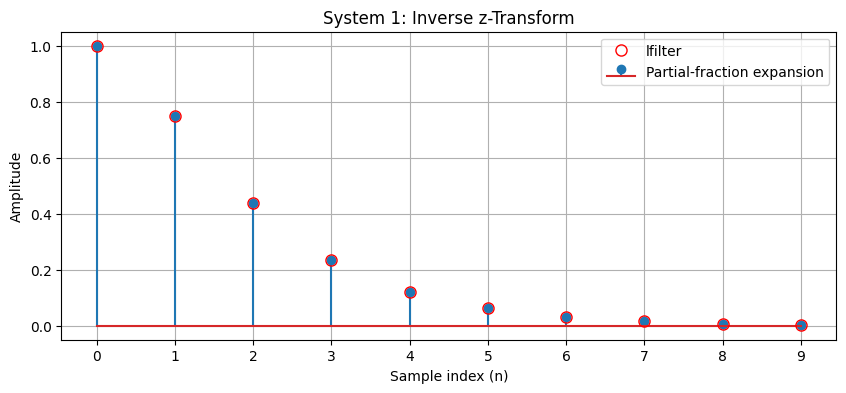

In [8]:

# Plot System 1 response

plt.figure(figsize=(10, 4))

plt.stem(n, x_pf,
         label="Partial-fraction expansion")

plt.plot(n, x_lf, "ro",
         fillstyle="none",
         markersize=8,
         label="lfilter")

plt.title("System 1: Inverse z-Transform")
plt.xlabel("Sample index (n)")
plt.ylabel("Amplitude")
plt.xticks(n)
plt.legend()
plt.grid(True)
plt.show()


In [9]:

# System 2: Transfer function from Task 4.1

b2 = [1, 1]
a2 = [1, -0.75, 0.125]

# Partial-fraction expansion
r2, p2, k2 = signal.residuez(b2, a2)

print("Residues:", r2)
print("Poles:", p2)
print("Direct terms:", k2)

# Inverse z-transform using residues
h_pf = sum(
    ri * pi**n for ri, pi in zip(r2, p2)
).real

# Impulse response using lfilter
h_lf = signal.lfilter(b2, a2, impulse)

# Analytical closed-form expression
h_closed = 6*(0.5**n) - 5*(0.25**n)

print("Partial-fraction response:",
      np.round(h_pf, 6))

print("lfilter response:",
      np.round(h_lf, 6))

print("Closed-form response:",
      np.round(h_closed, 6))

print("Partial fractions match lfilter:",
      np.allclose(h_pf, h_lf))

print("Partial fractions match closed form:",
      np.allclose(h_pf, h_closed))


Residues: [-5.  6.]
Poles: [0.25 0.5 ]
Direct terms: []
Partial-fraction response: [1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
lfilter response: [1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
Closed-form response: [1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
Partial fractions match lfilter: True
Partial fractions match closed form: True


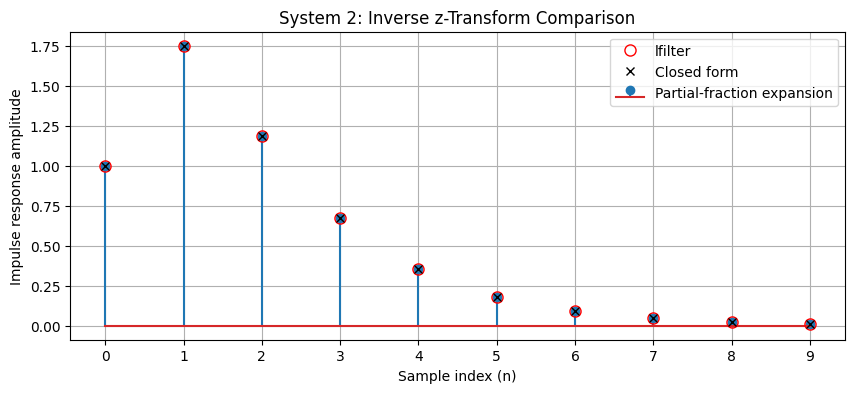

In [10]:

# Compare the three methods for System 2

plt.figure(figsize=(10, 4))

plt.stem(n, h_pf,
         label="Partial-fraction expansion")

plt.plot(n, h_lf, "ro",
         markersize=8,
         fillstyle="none",
         label="lfilter")

plt.plot(n, h_closed, "kx",
         markersize=6,
         label="Closed form")

plt.title("System 2: Inverse z-Transform Comparison")
plt.xlabel("Sample index (n)")
plt.ylabel("Impulse response amplitude")
plt.xticks(n)
plt.legend()
plt.grid(True)
plt.show()


,Sample n,System 1,System 2
0,0,1.000000,1.000000
1,1,0.750000,1.750000
2,2,0.437500,1.187500
3,3,0.234375,0.671875
4,4,0.121094,0.355469
5,5,0.061523,0.182617
6,6,0.031006,0.092529
7,7,0.015564,0.046570
8,8,0.007797,0.023361
9,9,0.003902,0.011700


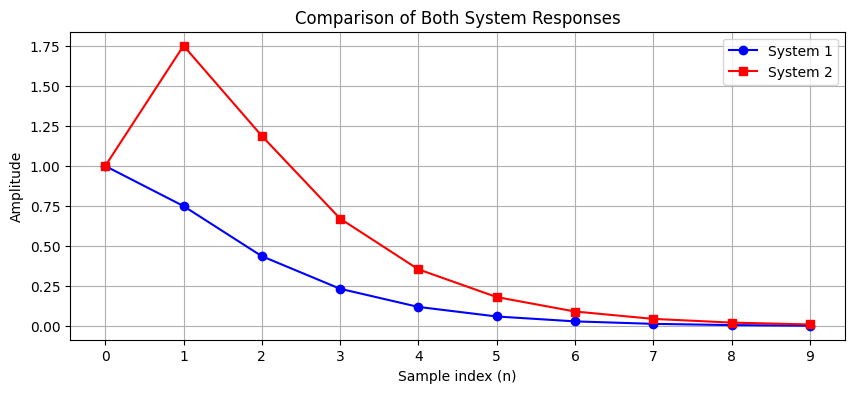

In [11]:

# Compare System 1 and System 2

import pandas as pd

comparison = pd.DataFrame({
    "Sample n": n,
    "System 1": x_pf,
    "System 2": h_pf
})

display(comparison.round(6))

plt.figure(figsize=(10, 4))

plt.plot(n, x_pf, "bo-",
         label="System 1")

plt.plot(n, h_pf, "rs-",
         label="System 2")

plt.title("Comparison of Both System Responses")
plt.xlabel("Sample index (n)")
plt.ylabel("Amplitude")
plt.xticks(n)
plt.legend()
plt.grid(True)
plt.show()


### Task 4.2 — Observations and Discussion

The inverse z-transform of two discrete-time systems was obtained using SciPy's residuez function through partial-fraction expansion.

For the first system, the calculated residues were −1 and 2, corresponding to poles located at 0.25 and 0.5, respectively. These results agreed with the pre-lab partial-fraction calculations.

For the second system, the calculated residues were −5 and 6, while the pole locations remained unchanged.

The inverse z-transform of the second system was confirmed to be:

h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ, for n ≥ 0.

The results obtained using partial-fraction expansion, SciPy's lfilter function and the analytical closed-form expression were identical within numerical tolerance.

Both systems exhibited impulse responses that decayed towards zero because their poles were located strictly inside the unit circle.

Although the systems had identical poles, their different numerator coefficients resulted in different residues and impulse response amplitudes.

The experiment demonstrated that partial-fraction expansion is an effective technique for converting rational z-domain expressions into discrete-time sequences.


## Task 4.3 — Pole Position and the Impulse Response

**Objective:** To investigate the effects of pole
radius on the impulse response, frequency response,
resonance, oscillation and stability of a
second-order discrete-time system.


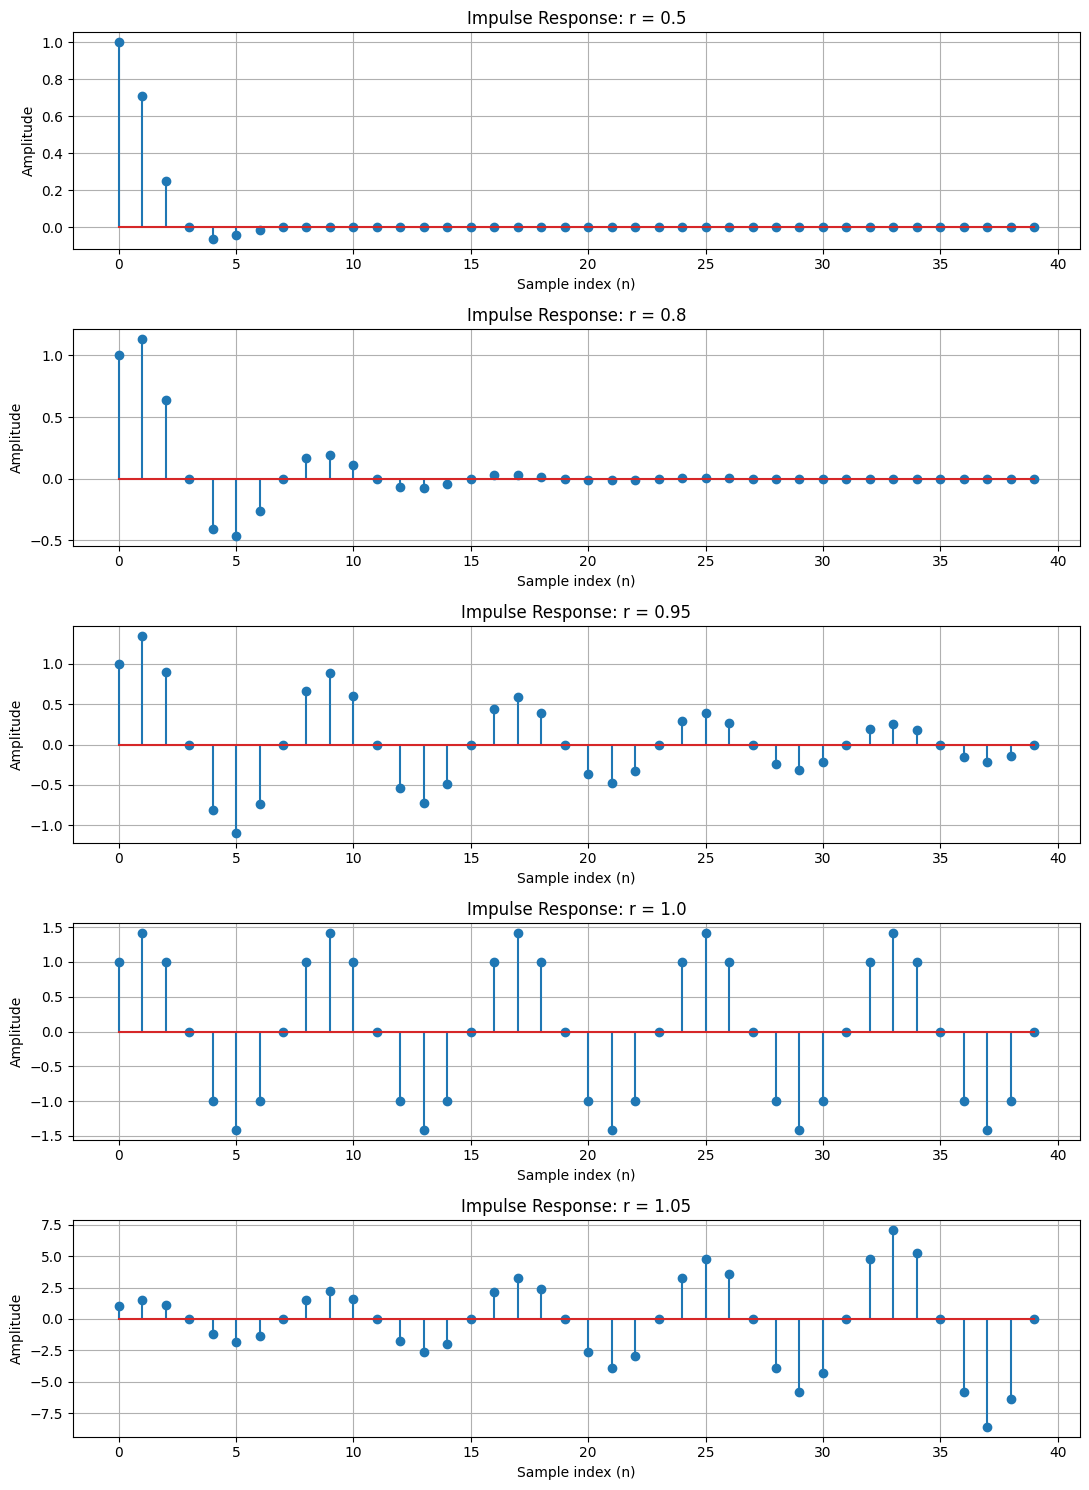

In [12]:

# Task 4.3: Effect of pole radius

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Pole radii
radii = [0.5, 0.8, 0.95, 1.0, 1.05]

# Constant pole angle
theta = np.pi / 4

# Generate 40 samples
N = 40
n = np.arange(N)

# Generate unit impulse
impulse = np.zeros(N)
impulse[0] = 1

# Store impulse responses
responses = {}

fig, axes = plt.subplots(5, 1, figsize=(11, 15))

for ax, r in zip(axes, radii):

    b = [1]

    a = [1, -2*r*np.cos(theta), r**2]

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    responses[r] = h

    # Plot impulse response
    ax.stem(n, h)

    ax.set_title(f"Impulse Response: r = {r}")
    ax.set_xlabel("Sample index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


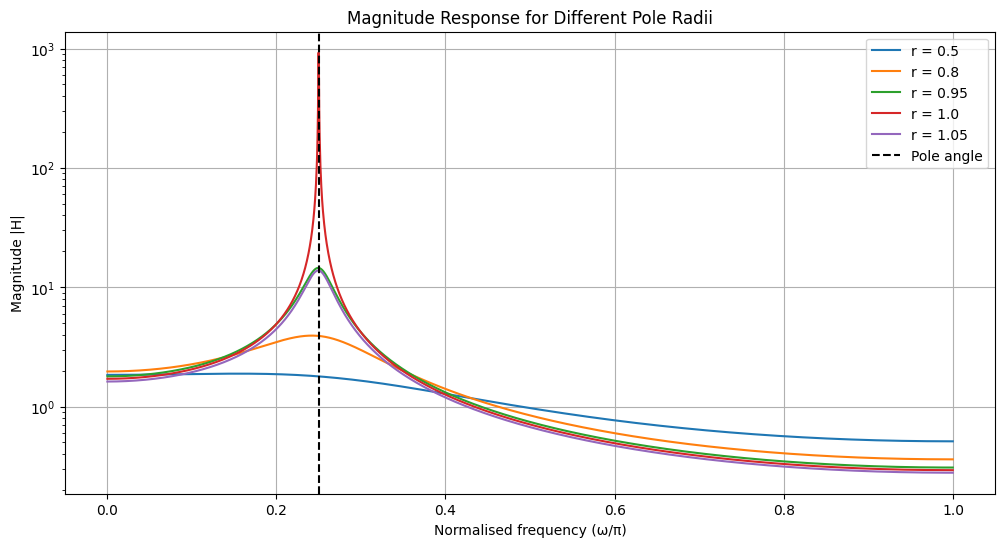

In [13]:

# Frequency response for different pole radii

plt.figure(figsize=(12, 6))

for r in radii:

    b = [1]

    a = [1, -2*r*np.cos(theta), r**2]

    # Frequency grid avoiding the exact pole angle
    w = (np.arange(2048) + 0.5) * np.pi / 2048

    # Calculate frequency response
    w, H = signal.freqz(b, a, worN=w)

    # Plot magnitude
    plt.plot(w/np.pi, np.abs(H),
             label=f"r = {r}")

plt.axvline(0.25, color="black",
            linestyle="--",
            label="Pole angle")

plt.title("Magnitude Response for Different Pole Radii")
plt.xlabel("Normalised frequency (ω/π)")
plt.ylabel("Magnitude |H|")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()


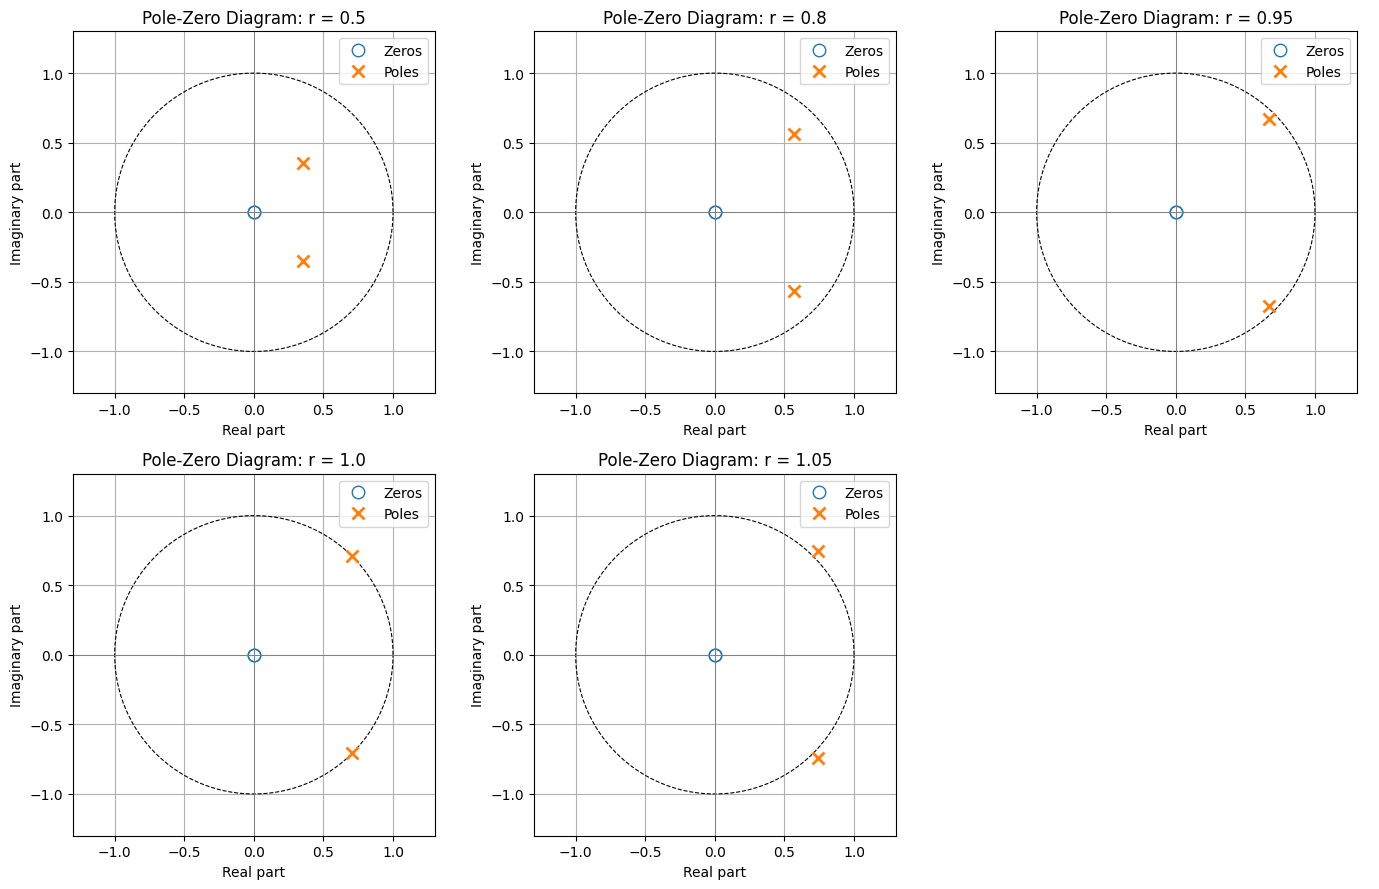

In [14]:

# Pole-zero diagrams for different radii

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, r in zip(axes.flat, radii):

    b = [1]

    a = [1, -2*r*np.cos(theta), r**2]

    z, p = zplane(b, a, ax)

    ax.set_title(f"Pole-Zero Diagram: r = {r}")

    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)

# Remove unused subplot
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()


In [15]:

# Stability classification

import pandas as pd

results = []

for r in radii:

    a = [1, -2*r*np.cos(theta), r**2]

    poles = np.roots(a)

    max_radius = np.max(np.abs(poles))

    if np.isclose(max_radius, 1):
        status = "Marginal (not BIBO stable)"

    elif max_radius < 1:
        status = "Stable"

    else:
        status = "Unstable"

    results.append({
        "Pole Radius": r,
        "Pole 1": np.round(poles[0], 4),
        "Pole 2": np.round(poles[1], 4),
        "Maximum Magnitude": round(max_radius, 4),
        "Stability": status
    })

stability_table = pd.DataFrame(results)

display(stability_table)


,Pole Radius,Pole 1,Pole 2,Maximum Magnitude,Stability
0,0.50,0.3536+0.3536j,0.3536-0.3536j,0.50,Stable
1,0.80,0.5657+0.5657j,0.5657-0.5657j,0.80,Stable
2,0.95,0.6718+0.6718j,0.6718-0.6718j,0.95,Stable
3,1.00,0.7071+0.7071j,0.7071-0.7071j,1.00,Marginal (not BIBO stable)
4,1.05,0.7425+0.7425j,0.7425-0.7425j,1.05,Unstable


### Task 4.3 — Observations and Discussion

The effects of pole position on the impulse response and magnitude frequency response of a second-order discrete-time system were investigated using five different pole radii: 0.5, 0.8, 0.95, 1.0 and 1.05.

For a pole radius of 0.5, the impulse response decayed rapidly towards zero. Increasing the radius to 0.8 and 0.95 resulted in slower decay and longer-lasting oscillations.

As the stable poles approached the unit circle, the resonance peak became sharper and its bandwidth decreased.

When the pole radius was equal to 1.0, the impulse response exhibited sustained oscillations without decay. Although the impulse response remained bounded, the system was not BIBO stable.

When the pole radius was increased to 1.05, the oscillation envelope grew exponentially, indicating an unstable system.

The oscillation period remained constant at eight samples because the pole angle was maintained at π/4 throughout the experiment.

The systems with pole radii of 0.5, 0.8 and 0.95 were BIBO stable, while those with radii of 1.0 and 1.05 were not.

The experiment demonstrated that the pole radius determines the decay rate, resonance sharpness and stability of a discrete-time system, while the pole angle determines its oscillation frequency.


## Task 4.4 — Stability of Given Systems

**Objective:** To investigate the stability of
four discrete-time systems using pole-zero
diagrams, pole magnitudes and impulse responses.


In [16]:

# Task 4.4: Stability of given systems

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd

# Define the four systems
systems = {
    "System A": ([1], [1, -1.6, 0.89]),
    "System B": ([1, 1], [1, -2.5, 1]),
    "System C": ([1], [1, 0.5, -0.5]),
    "System D": ([1, 0, 0, 0, -1], [1])
}

results = []

for name, (b, a) in systems.items():

    # Pad coefficients
    N = max(len(b), len(a))

    b_pad = np.pad(b, (0, N - len(b)))
    a_pad = np.pad(a, (0, N - len(a)))

    # Calculate poles and zeros
    z, p, k = signal.tf2zpk(b_pad, a_pad)

    max_radius = np.max(np.abs(p)) if len(p) else 0

    # Classify stability
    if np.isclose(max_radius, 1):
        status = "Marginal (not BIBO stable)"

    elif max_radius < 1:
        status = "Stable"

    else:
        status = "Unstable"

    print(name)
    print("Poles:", np.round(p, 6))
    print("Zeros:", np.round(z, 6))
    print("Maximum pole magnitude:",
          round(max_radius, 6))
    print("Stability:", status)
    print("-" * 40)

    results.append({
        "System": name,
        "Maximum Pole Magnitude": max_radius,
        "Stability": status
    })


System A
Poles: [0.8+0.5j 0.8-0.5j]
Zeros: [0. 0.]
Maximum pole magnitude: 0.943398
Stability: Stable
----------------------------------------
System B
Poles: [2.  0.5]
Zeros: [-1.  0.]
Maximum pole magnitude: 2.0
Stability: Unstable
----------------------------------------
System C
Poles: [-1.   0.5]
Zeros: [0. 0.]
Maximum pole magnitude: 1.0
Stability: Marginal (not BIBO stable)
----------------------------------------
System D
Poles: [0. 0. 0. 0.]
Zeros: [-1.+0.j  0.+1.j  0.-1.j  1.+0.j]
Maximum pole magnitude: 0.0
Stability: Stable
----------------------------------------


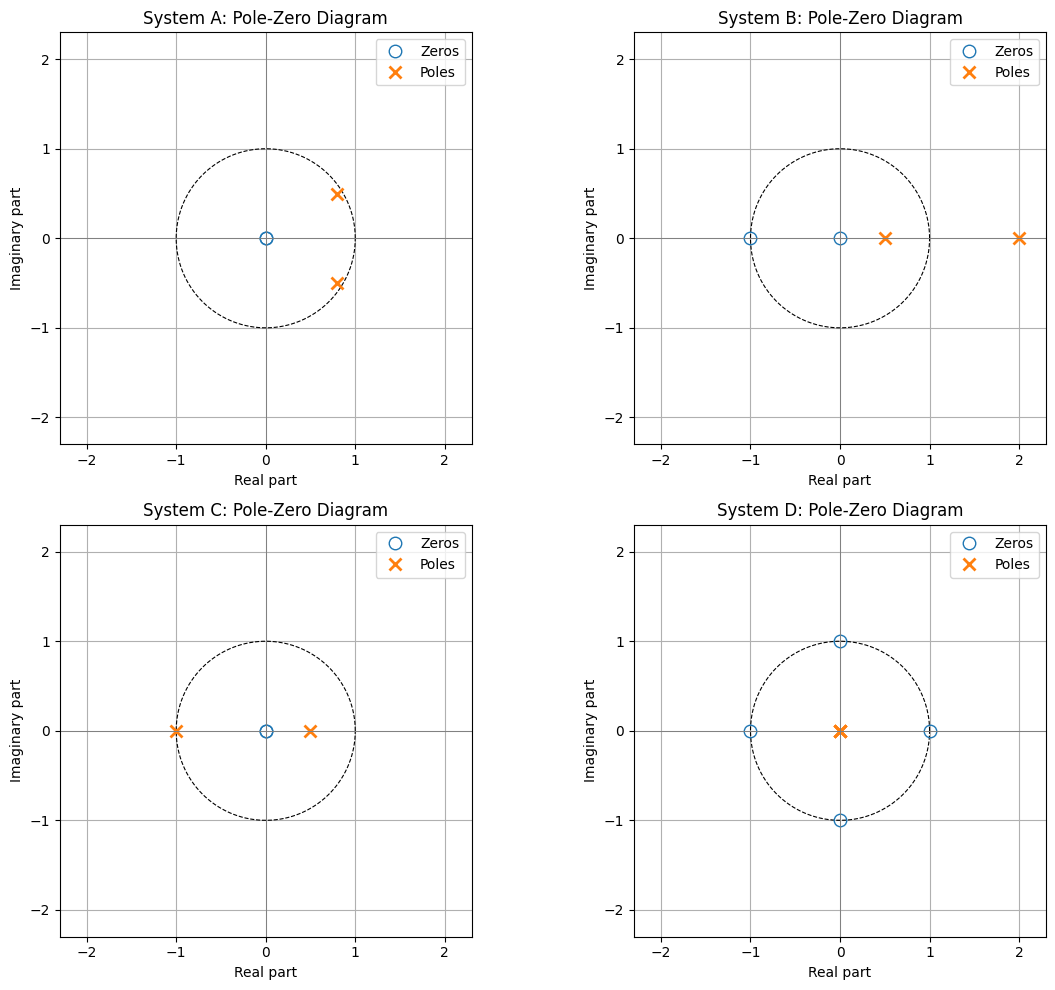

In [17]:

# Plot pole-zero diagrams

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, (b, a)) in zip(
        axes.flat, systems.items()):

    z, p = zplane(b, a, ax)

    ax.set_title(f"{name}: Pole-Zero Diagram")

    ax.set_xlim(-2.3, 2.3)
    ax.set_ylim(-2.3, 2.3)

plt.tight_layout()
plt.show()


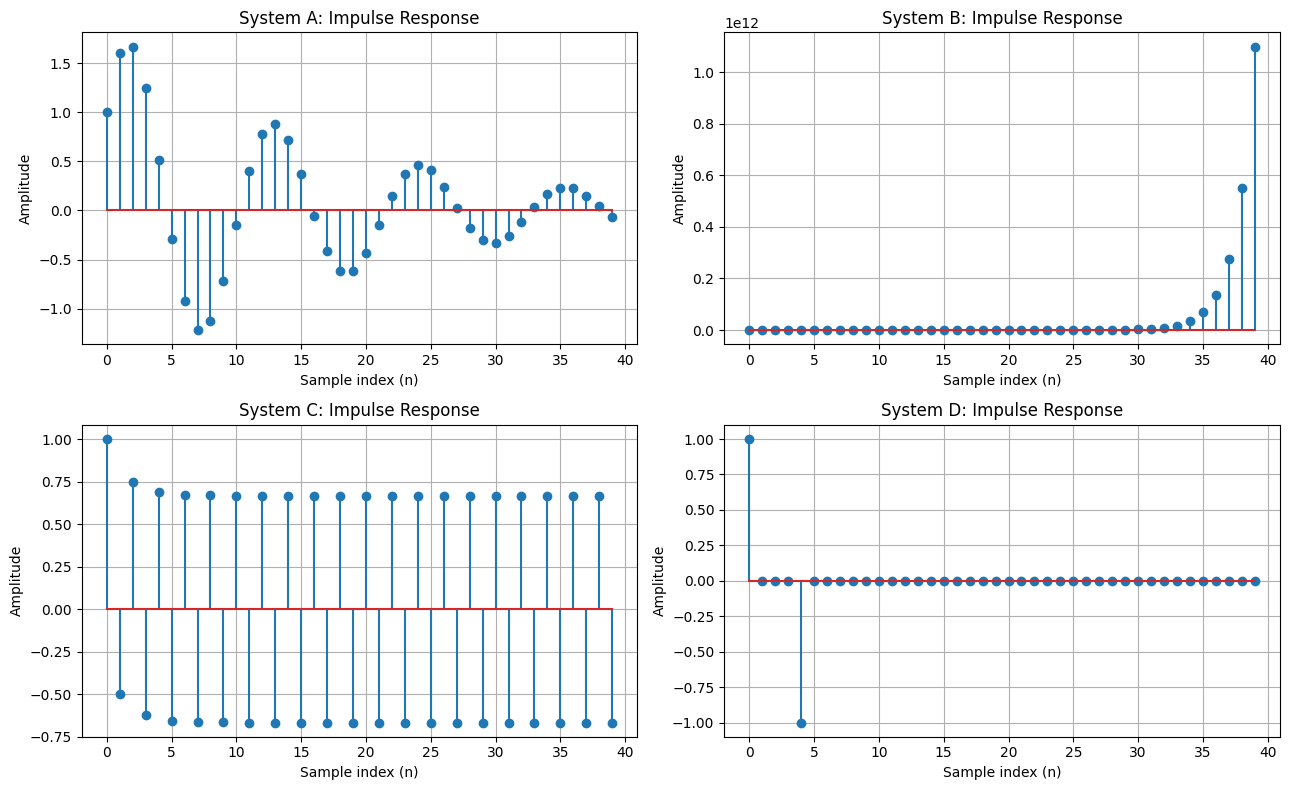

In [18]:

# Impulse response of each system

N = 40
n = np.arange(N)

impulse = np.zeros(N)
impulse[0] = 1

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, (name, (b, a)) in zip(
        axes.flat, systems.items()):

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    # Plot impulse response
    ax.stem(n, h)

    ax.set_title(f"{name}: Impulse Response")
    ax.set_xlabel("Sample index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


In [19]:

# Display stability classification

stability_table = pd.DataFrame(results)

display(stability_table.round(6))


,System,Maximum Pole Magnitude,Stability
0,System A,0.943398,Stable
1,System B,2.000000,Unstable
2,System C,1.000000,Marginal (not BIBO stable)
3,System D,0.000000,Stable


### Task 4.4 — Observations and Discussion

Four discrete-time systems were investigated to determine their stability using pole-zero diagrams, pole magnitudes and impulse responses.

**System A:** The system contained complex-conjugate poles at 0.8 ± j0.5, with magnitudes of approximately 0.9434. Both poles were located inside the unit circle, and the impulse response exhibited decaying oscillations. Therefore, the system was BIBO stable.

**System B:** The system contained poles at 2 and 0.5. The pole at 2 was located outside the unit circle, causing the impulse response to grow exponentially. Therefore, the system was unstable.

**System C:** The system contained poles at −1 and 0.5. The pole at −1 was located exactly on the unit circle, producing sustained oscillations without decay. Although its impulse response remained bounded, it was not absolutely summable. Therefore, the system was not BIBO stable.

**System D:** The system exhibited a finite impulse response with non-zero samples only at n = 0 and n = 4. Its impulse response was absolutely summable, confirming that it was a stable FIR system.

The experiment demonstrated that the stability of a causal rational discrete-time system depends on the locations of its poles relative to the unit circle. Systems A and D were BIBO stable, while Systems B and C were not.


## Task 4.5 — Design a Resonator

**Objective:** To design a second-order digital
resonator with a resonance frequency of 1 kHz,
a sampling frequency of 8 kHz and a pole radius
of 0.97, and investigate its performance by
filtering white noise.


In [20]:

# Task 4.5: Design a digital resonator

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Design specifications
fs = 8000
f0 = 1000
r = 0.97

# Calculate pole angle
theta = 2 * np.pi * f0 / fs

# Numerator coefficients
b = [1, 0, -1]

# Denominator coefficients
a = [1, -2*r*np.cos(theta), r**2]

# Calculate poles and zeros
zeros, poles, gain = signal.tf2zpk(b, a)

print("Sampling frequency:", fs, "Hz")
print("Resonance frequency:", f0, "Hz")
print("Pole radius:", r)

print("Pole angle:",
      np.degrees(theta), "degrees")

print("Numerator coefficients:", b)

print("Denominator coefficients:",
      np.round(a, 6))

print("Zeros:", np.round(zeros, 6))

print("Poles:", np.round(poles, 6))

print("Pole magnitudes:", np.abs(poles))

print("System is stable:",
      np.all(np.abs(poles) < 1))


Sampling frequency: 8000 Hz
Resonance frequency: 1000 Hz
Pole radius: 0.97
Pole angle: 45.0 degrees
Numerator coefficients: [1, 0, -1]
Denominator coefficients: [ 1.       -1.371787  0.9409  ]
Zeros: [-1.  1.]
Poles: [0.685894+0.685894j 0.685894-0.685894j]
Pole magnitudes: [0.97 0.97]
System is stable: True


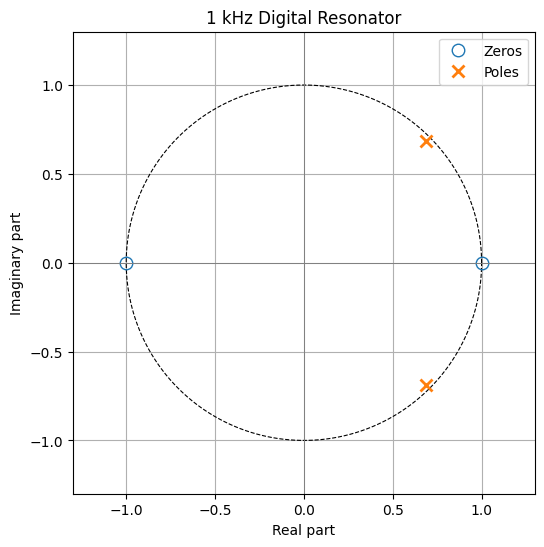

In [21]:

# Resonator pole-zero diagram

fig, ax = plt.subplots(figsize=(6, 6))

zplane(b, a, ax)

ax.set_title("1 kHz Digital Resonator")
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)

plt.show()


Measured peak frequency: 1000.49 Hz
Peak gain: 30.59 dB


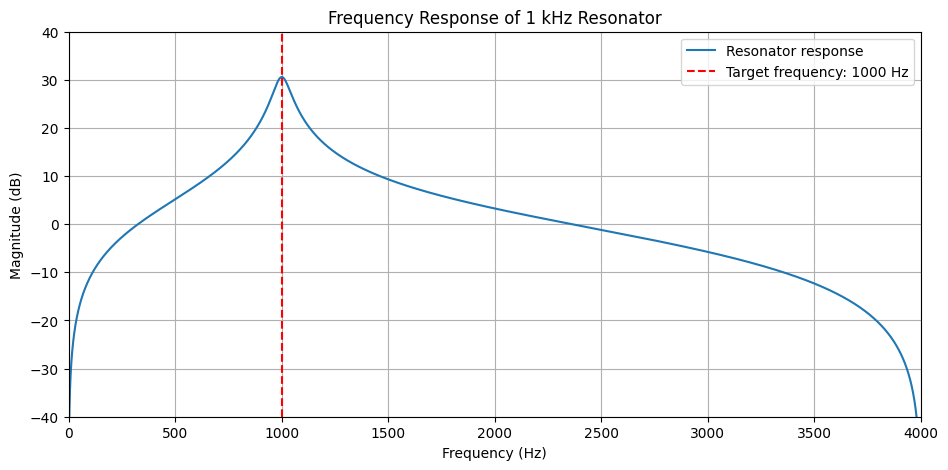

In [22]:

# Calculate frequency response in Hz

frequencies, H = signal.freqz(
    b, a, worN=8192, fs=fs
)

# Magnitude in decibels
magnitude_db = 20*np.log10(
    np.maximum(np.abs(H), 1e-12)
)

# Find peak frequency
peak_index = np.argmax(np.abs(H))
peak_frequency = frequencies[peak_index]

print("Measured peak frequency:",
      round(peak_frequency, 2), "Hz")

print("Peak gain:",
      round(magnitude_db[peak_index], 2), "dB")

# Plot frequency response
plt.figure(figsize=(11, 5))

plt.plot(frequencies, magnitude_db,
         label="Resonator response")

plt.axvline(f0, color="red",
            linestyle="--",
            label="Target frequency: 1000 Hz")

plt.title("Frequency Response of 1 kHz Resonator")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0, fs/2)
plt.ylim(-40, 40)
plt.legend()
plt.grid(True)
plt.show()


Duration: 3 seconds
Number of samples: 24000
Sampling frequency: 8000 Hz


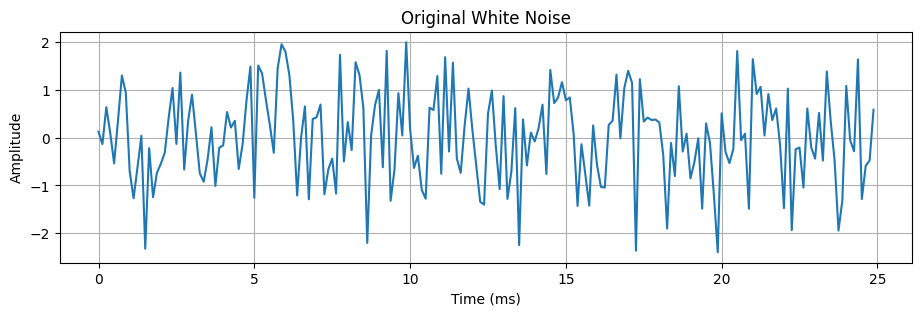

In [23]:

# Generate white noise

duration = 3

rng = np.random.default_rng(0)

t = np.arange(fs * duration) / fs

x = rng.standard_normal(len(t))

print("Duration:", duration, "seconds")
print("Number of samples:", len(x))
print("Sampling frequency:", fs, "Hz")

# Plot the first 200 samples
plt.figure(figsize=(11, 3))

plt.plot(t[:200]*1000, x[:200])

plt.title("Original White Noise")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


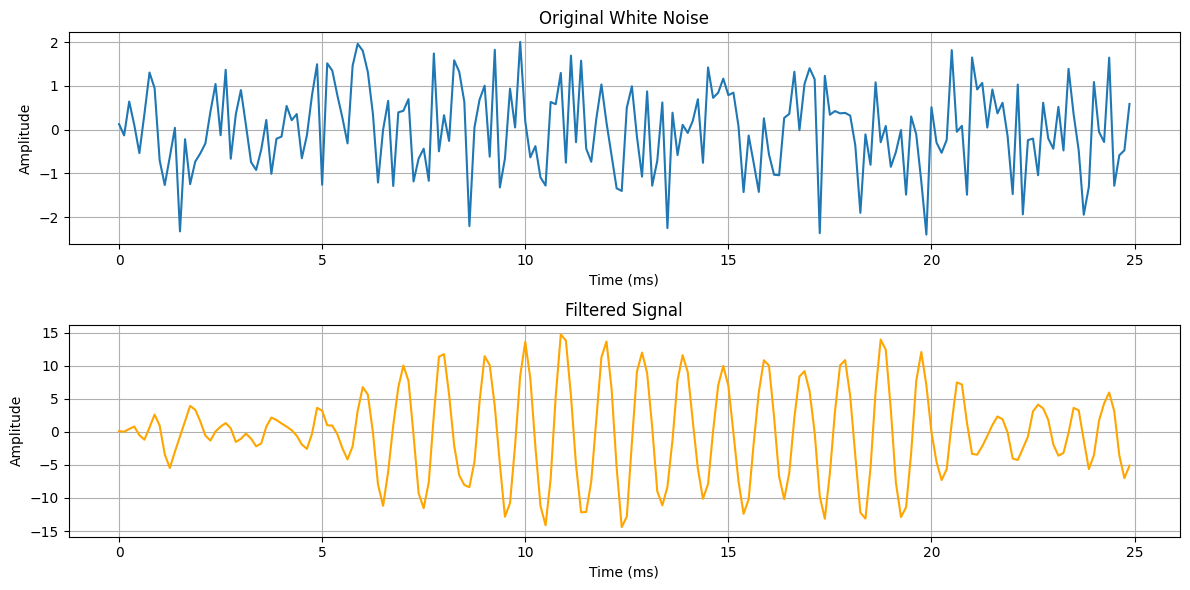

In [24]:

# Filter white noise using the resonator

y = signal.lfilter(b, a, x)

# Compare input and output signals

fig, axes = plt.subplots(
    2, 1, figsize=(12, 6)
)

axes[0].plot(t[:200]*1000, x[:200])

axes[0].set_title("Original White Noise")
axes[0].set_xlabel("Time (ms)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].plot(t[:200]*1000, y[:200],
             color="orange")

axes[1].set_title("Filtered Signal")
axes[1].set_xlabel("Time (ms)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [25]:

# Listen to the input and output signals

from IPython.display import Audio, display

print("Original White Noise:")

display(Audio(x, rate=fs, normalize=True))

print("Filtered Resonator Output:")

display(Audio(y, rate=fs, normalize=True))


Original White Noise:


Filtered Resonator Output:


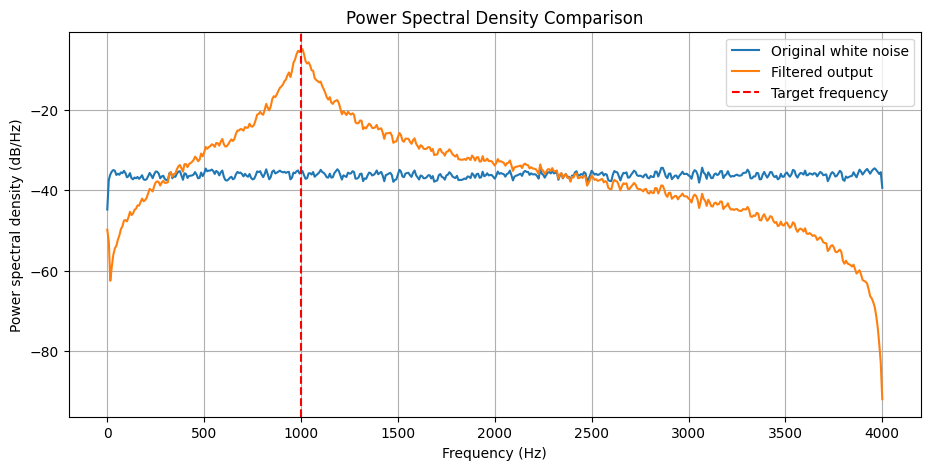

In [26]:

# Compare power spectral densities

f_x, Pxx = signal.welch(
    x, fs=fs, nperseg=1024
)

f_y, Pyy = signal.welch(
    y, fs=fs, nperseg=1024
)

plt.figure(figsize=(11, 5))

plt.plot(f_x,
         10*np.log10(np.maximum(Pxx, 1e-20)),
         label="Original white noise")

plt.plot(f_y,
         10*np.log10(np.maximum(Pyy, 1e-20)),
         label="Filtered output")

plt.axvline(1000, color="red",
            linestyle="--",
            label="Target frequency")

plt.title("Power Spectral Density Comparison")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power spectral density (dB/Hz)")
plt.legend()
plt.grid(True)
plt.show()


### Task 4.5 — Observations and Discussion

A second-order digital resonator was designed with a target resonance frequency of 1000 Hz, a sampling frequency of 8000 Hz and a pole radius of 0.97.

The calculated pole angle was π/4 radians, equivalent to 45 degrees. The complex-conjugate poles were located at approximately 0.685894 ± j0.685894.

Both poles were located strictly inside the unit circle, confirming that the designed resonator was BIBO stable.

Two zeros were placed at z = +1 and z = −1 to suppress the DC component and the Nyquist frequency of 4000 Hz, respectively.

The frequency response exhibited a sharp resonance near 1000 Hz, demonstrating band-pass filter behaviour.

White noise was generated and passed through the resonator using SciPy's lfilter function. The filtered signal exhibited more regular oscillations than the original white noise.

The power spectral density of the filtered signal showed that frequencies near 1000 Hz were emphasised relative to frequencies outside the resonance region.

The audio comparison demonstrated that the resonator transformed broadband white noise into narrow-band noise with a noticeable pitch.

The experiment demonstrated that digital filters can be designed by strategically placing poles and zeros in the z-plane to achieve desired frequency response characteristics.

## Week 4 — Analysis Questions

### Question 1: Explain the effect of r on the bandwidth of the resonance in Task 4.3.

The pole radius determines the bandwidth and sharpness of the resonance in a discrete-time system.

When the pole radius is small, such as 0.5, the resonance is broad and the impulse response decays rapidly.

As the pole radius increases to 0.8 and 0.95, the resonance becomes sharper and its bandwidth decreases. The impulse response also takes longer to decay.

When the pole radius approaches one from below, the system becomes more frequency-selective because it emphasises a narrower range of frequencies.

At a pole radius of exactly one, the transfer function becomes singular at the pole frequency, and the system is no longer BIBO stable.

Therefore, increasing the pole radius towards one reduces the resonance bandwidth and increases frequency selectivity.

### Question 2: What happens to h(n) when a pole lies exactly on the unit circle?

When a simple, uncancelled pole lies exactly on the unit circle, its magnitude is equal to one.

For the complex-conjugate poles investigated in Task 4.3, the impulse response exhibits sustained oscillations without decaying towards zero.

Although the impulse response remains bounded, it is not absolutely summable. Therefore, the system does not satisfy the Bounded Input Bounded Output (BIBO) stability condition.

Such a system is commonly described as marginally stable in terms of its natural response, but it is not BIBO stable.

Repeated poles on the unit circle can also produce impulse responses that grow with time.

### Question 3: Why does placing zeros at z = ±1 make the resonator a band-pass filter?

Placing zeros at z = +1 and z = −1 suppresses the lowest and highest frequencies in the discrete-time frequency range.

The zero at z = +1 eliminates the DC component, corresponding to a frequency of 0 Hz.

The zero at z = −1 eliminates the Nyquist frequency, corresponding to half the sampling frequency. For a sampling frequency of 8000 Hz, the Nyquist frequency is 4000 Hz.

The complex-conjugate poles located near the unit circle create a resonance around the desired frequency of 1000 Hz.

The combination of these poles and zeros produces a band-pass response because frequencies around the resonance frequency are emphasised while frequencies towards DC and the Nyquist frequency are attenuated.

In [27]:

# Stability triangle verification

import numpy as np
import pandas as pd

coefficients = {
    "System A": (-1.6, 0.89),
    "System B": (-2.5, 1),
    "System C": (0.5, -0.5)
}

results = []

for name, (a1, a2) in coefficients.items():

    c1 = 1 + a1 + a2
    c2 = 1 - a1 + a2
    c3 = 1 - a2

    conditions = np.array([c1, c2, c3])

    if np.all(conditions > 1e-10):
        status = "Stable"

    elif np.any(conditions < -1e-10):
        status = "Unstable"

    else:
        status = "Boundary (not BIBO stable)"

    results.append({
        "System": name,
        "a1": a1,
        "a2": a2,
        "Condition 1": c1,
        "Condition 2": c2,
        "Condition 3": c3,
        "Stability": status
    })

triangle_results = pd.DataFrame(results)

display(triangle_results.round(4))


,System,a1,a2,Condition 1,Condition 2,Condition 3,Stability
0,System A,-1.6,0.89,0.29,3.49,0.11,Stable
1,System B,-2.5,1.00,-0.50,4.50,0.00,Unstable
2,System C,0.5,-0.50,1.00,0.00,1.50,Boundary (not BIBO stable)


### Question 4: Use the stability triangle to check your answers to Task 4.4 (a)–(c).

For a second-order discrete-time system with denominator coefficients a₁ and a₂, the stability conditions are:

1 + a₁ + a₂ > 0

1 − a₁ + a₂ > 0

1 − a₂ > 0

**System A:**

a₁ = −1.6, a₂ = 0.89

Condition 1 = 0.29

Condition 2 = 3.49

Condition 3 = 0.11

All three conditions are satisfied. Therefore, System A is stable.

**System B:**

a₁ = −2.5, a₂ = 1

Condition 1 = −0.5

Condition 2 = 4.5

Condition 3 = 0

The first and third conditions are not satisfied. Therefore, System B is unstable.

**System C:**

a₁ = 0.5, a₂ = −0.5

Condition 1 = 1

Condition 2 = 0

Condition 3 = 1.5

The second condition is not strictly satisfied. Therefore, System C lies on the stability boundary and is not BIBO stable.

The stability triangle results agree with the pole-zero diagrams and impulse response analysis obtained in Task 4.4.

## Conclusion

The Week 4 laboratory successfully investigated the z-transform, pole-zero representation, inverse z-transform and stability of discrete-time systems using Python in Google Colab.

A reusable pole-zero plotting function was developed to visualise pole and zero locations and determine system stability. Partial-fraction expansion was performed using SciPy's residuez function, and the results were verified using lfilter and analytical expressions.

The relationship between pole radius, impulse response decay, oscillation and resonance bandwidth was investigated. It was observed that systems with poles strictly inside the unit circle were BIBO stable, while systems with poles on or outside the unit circle were not.

Four different transfer functions were analysed, and their stability classifications were verified using pole-zero diagrams, impulse responses and the stability triangle.

A second-order digital resonator was also designed to emphasise frequencies around 1000 Hz. The resonator successfully transformed broadband white noise into narrow-band noise.

Overall, the laboratory improved practical understanding of z-domain analysis, digital system stability and filter design through strategic placement of poles and zeros.

## AI-Use Statement

**AI tool used:** ChatGPT by OpenAI.

ChatGPT was used to assist in understanding z-transform concepts, developing Python code, performing mathematical calculations, interpreting graphs and organising laboratory observations.

The Python code was executed in Google Colab, and the numerical results were compared with theoretical calculations, expected pole locations, impulse responses and stability conditions.

The partial-fraction expansion results were verified using SciPy's lfilter function and analytical expressions. System stability was also verified using the stability triangle.

The AI-generated assistance was reviewed and used to support my understanding of the laboratory activities.